# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [6]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [7]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv") 
usage = pd.read_csv("/datasets/usage.csv") 

In [9]:
plans.head()# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [8]:
users.head()# mostrar las primeras 5 filas de users

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [10]:
usage.head()# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [8]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [9]:
plans.info()# inspección de plans con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [13]:
users.info()# inspección de users con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [14]:
usage.info()# inspección de usage con .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
users.isna().sum()
print(users.isna().sum())
print((users.isna().sum()/users.shape[0])*100)
    

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [11]:

usage.isna().sum()
print(usage.isna().sum())



id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
-  En users: la columna "city" tiene 469 valores nulos que representan el 11.725% de los registros.Churn_date tiene 3534 valores nulos, equivalentes al 88.350% de los registros.
- En usage la columna "date" indica 50 registros nulos. "duration" untotal de 22,076 nulos y "lenght" un total de 17,896 nulos. 
-  
- Indica qué harías: ¿imputar, eliminar, ignorar?
- city: probablemente sí sea un dato faltante que requiere análisis o imputación.
churn_date: en un dataset de telecomunicaciones suele ser normal que esté vacío para los clientes que no han cancelado el servicio. En ese caso, los nulos no representan un error sino un posible cliente activo.

En cuanto al dataset "usage" 50 valores nulos (0.04%), que representan una proporción mínima de los registros y deben revisarse antes del análisis. 
Por otro lado, duration presenta 22,076 valores nulos y length 17,896. Estos valores ausentes parecen estar asociados al tipo de comunicación registrada, ya que las llamadas no requieren longitud de mensaje y los mensajes de texto no requieren duración de llamada, por lo que no necesariamente representan errores en los datos. Aunque por tener porcentajes mayores al 10%, vale la pena investigarlos. 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
print(users.describe())

            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


- La columna `user_id` Es un identificador unico de usuarios con valores entre entre 10000 y 13999. 
- La columna `age` es la edad de usuarios donde en promedio tienen 33.74 años,  con un claro outlier en el valor minimo al marcar -999. La mediana marca 47 años lo que se desvia por mucho de la media 33.74 años, por lo que es probable que el outlier afecte directamente a la mediana. 

In [13]:
print(usage.describe())# explorar columnas numéricas de usage

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


- Las columnas `id` y `user_id` ambas representan identificadores de usuarios.
- Las columnas La variable duration representa la duración de las llamadas. Presenta una duración promedio de 5.2 minutos, con valores entre 0 y 120 minutos.
- La variable length representa la longitud de los mensajes. Tiene una media de 52 caracteres y una mediana de 50, lo que sugiere una distribución relativamente equilibrada

In [14]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].value_counts())


Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64
Basico     2595
Premium    1405
Name: plan, dtype: int64


- La columna `city` indica el nombre de la ciudad o ciudades donde hay planes contratados, y la cantidad de los mismos.
- La columna `plan` categoriza los planes contratados en dos> basico o premium. 

In [15]:
# explorar columna categórica de usage
usage['type'] # completa el código
for col in usage:
    print(usage[col].value_counts())

2049     1
35492    1
25241    1
31386    1
29339    1
        ..
17730    1
19779    1
30020    1
32069    1
2047     1
Name: id, Length: 40000, dtype: int64
13819    27
13100    22
13772    22
13255    22
13475    21
         ..
12448     2
11891     2
10226     2
13923     2
12058     1
Name: user_id, Length: 3999, dtype: int64
text    22092
call    17908
Name: type, dtype: int64
2024-06-13 03:59:52.439810994    1
2024-02-27 12:13:54.860871521    1
2024-05-13 08:44:21.186529662    1
2024-01-21 00:40:32.220805520    1
2024-06-02 17:46:38.079951998    1
                                ..
2024-01-24 17:11:12.586814670    1
2024-06-15 12:08:43.813095326    1
2024-04-15 09:27:57.011925298    1
2024-04-28 06:39:27.959198980    1
2024-04-22 14:15:09.922748068    1
Name: date, Length: 39950, dtype: int64
0.21     47
0.03     43
1.25     43
0.02     43
0.84     43
         ..
46.69     1
42.73     1
17.42     1
21.79     1
16.02     1
Name: duration, Length: 2090, dtype: int64
47.0     460
5

- La columna `type` identifica si el uso del servicio fue un mensaje de texto o llamada.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

-ID: Los 40,000 registros tienen un identificador único lo que da certeza de no tener duplicados. 
-user_id: Existen 3,999 usuarios únicos para 40,000 registros de uso.
-type: La distribución está relativamente balanceada entre mensajes de texto (22,092 registros) y llamadas (17,908 registros).
-date: Hay 39,950 fechas únicas para 40,000 registros, lo que sugiere que casi todas las actividades ocurrieron en momentos distintos. Sin embargo, previamente se identificaron 50 valores nulos, que deben revisarse.
-duration: La mayoría de las duraciones se concentra en llamadas cortas. Existen algunos valores muy frecuentes de pocos minutos y unas pocas llamadas largas
-length: La longitud de los mensajes se concentra alrededor de 45 a 53 caracteres, aunque existen algunos mensajes excepcionalmente largos que podrían considerarse valores atípicos.

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?
Hay un outlier en la columna age de -999.Este valor probablemente se utilizo como sentinel, por lo que se recomienda reemplazarlo por un valor nulo para evitar distorsiones estadísticas. 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"])
users.dtypes

user_id                int64
first_name            object
last_name             object
age                    int64
city                  object
reg_date      datetime64[ns]
plan                  object
churn_date            object
dtype: object

In [22]:
# Convertir a fecha la columna `date` de usage
usage['date'] = users['date'] = pd.to_datetime(usage["date"]) 
usage.dtypes

id                   int64
user_id              int64
type                object
date        datetime64[ns]
duration           float64
length             float64
dtype: object

In [20]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

En `reg_date`, 4 años unicos: 2022, 2026, 2023 y 2024

In [23]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, Unicamente encontramos el año 2024 y un NAN.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso: Users detecta registros del 2022 al 2024. 

En usage encontramos el año 2024 y Nan, por lo que se recomienda investigar registros  antes de continuar el análisis para evitar errores de cálculo. 

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos) Aparecen datos nulos que merece la pena validar. 
- ¿Qué harías con ellas? Identificarlos usando .isna()].head()

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [24]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [25]:

# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?",pd.NA)

# Verificar cambios
users['city'].describe()


count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [26]:


# Marcar fechas futuras como NA para reg_date
users.loc[(users['reg_date'].dt.year > 2024),"reg_date"] = pd.NaT

# Verificar cambios
users['reg_date'].describe()



count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [27]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duration"].isna().groupby(usage["type"]).sum()

type
call        0
text    22076
Name: duration, dtype: int64

In [28]:
# Verificación MAR en usage (Missing At Random) para length
usage["length"].isna().groupby(usage["type"]).sum()

type
call    17896
text        0
Name: length, dtype: int64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Para duration: Hay 22076 registros nulos en la categoria Text y tiene sentido pues duracion es una metrica esperada unicamente para llamadas.

En length: El caso es opuesto con 17896 nulos en call, pues esta metrica solo aplica a mensajes de texto.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [29]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({"is_text":"sum","is_call":"sum","duration": "sum"}).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [30]:

# Renombrar columnas
usage_agg = usage_agg.rename(columns={"is_text":"cant_mensajes","is_call":"cant_llamadas","duration":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [33]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(usage_agg , users, on= "user_id" )
user_profile.head(5)


,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,date
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2024-01-01 00:00:00.000000000
1,10001,5,10,33.18,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2024-01-01 00:06:30.969774244
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2024-01-01 00:13:01.939548488
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2024-01-01 00:19:32.909322733
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2024-01-01 00:26:03.879096977


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [34]:
# Resumen estadístico de las columnas numéricas
print(user_profile.describe())

            user_id  cant_mensajes  cant_llamadas  cant_minutos_llamada  \
count   3999.000000    3999.000000    3999.000000           3999.000000   
mean   11999.729432       5.524381       4.478120             23.317054   
std     1154.898108       2.358416       2.144238             18.168095   
min    10000.000000       0.000000       0.000000              0.000000   
25%    10999.500000       4.000000       3.000000             11.120000   
50%    12000.000000       5.000000       4.000000             19.780000   
75%    12999.500000       7.000000       6.000000             31.415000   
max    13999.000000      17.000000      15.000000            155.690000   

               age  
count  3999.000000  
mean     48.124531  
std      17.692032  
min      18.000000  
25%      33.000000  
50%      47.000000  
75%      63.000000  
max      79.000000  


In [39]:
# Distribución porcentual del tipo de plan
print(user_profile["plan"].value_counts(normalize=True)*100)

Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

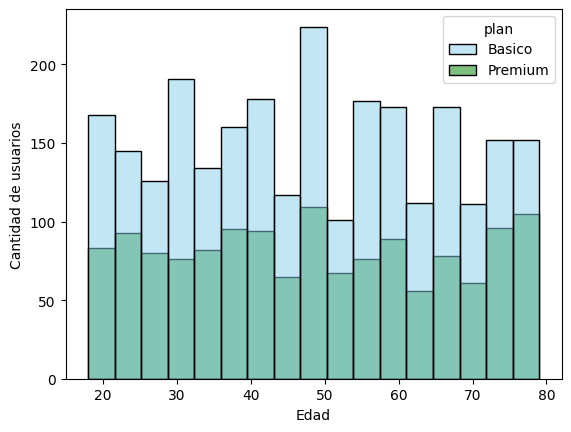

In [46]:
# Histograma para visualizar la edad (age)

sns.histplot(data= user_profile, x='age', hue='plan', palette=['skyblue','green'])
plt.xlabel('Edad')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights: 
- La distribución de edades es relativamente uniforme entre los 20 y 80 años para ambos planes, sin concentraciones marcadas en un rango específico. Sin embargo, el plan Básico presenta  una mayor cantidad de usuarios en todos los grupos de edad,comparado con el plan Premium, lo que sugiere que la diferencia principal entre los planes está en su nivel de contratacion y no en la edad de los clientes.

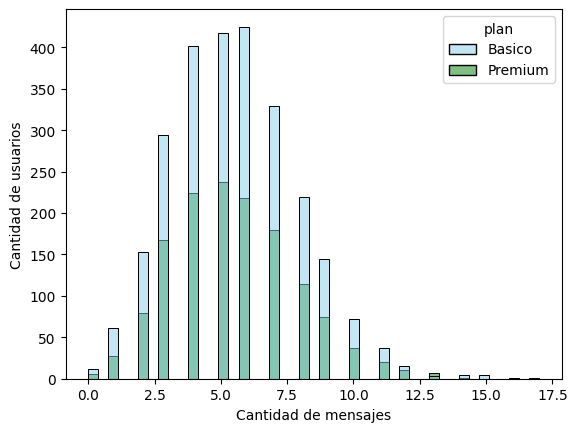

In [45]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data= user_profile, x='cant_mensajes', hue='plan', palette=['skyblue','green'])
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La distribución de mensajes es similar para los usuarios de los planes Básico y Premium, con una mayor concentración entre 4 y 7 mensajes por período. Sin embargo, el plan Básico presenta un volumen mayor de usuarios en todos los niveles de uso, lo que refleja una mayor base de clientes más que una diferencia en los patrones de mensajería.

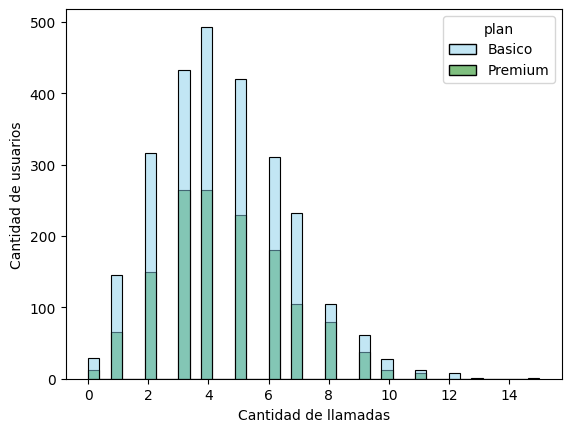

In [47]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data= user_profile, x='cant_llamadas', hue='plan', palette=['skyblue','green'])
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La cantidad de llamadas presenta una distribución aproximadamente normal, concentrándose principalmente entre 3 y 6 llamadas por usuario. Tanto los planes Básico como Premium muestran un patrón muy similar de uso, aunque el plan Básico registra un mayor número de usuarios en cada nivel de llamadas debido a su mayor base de clientes.

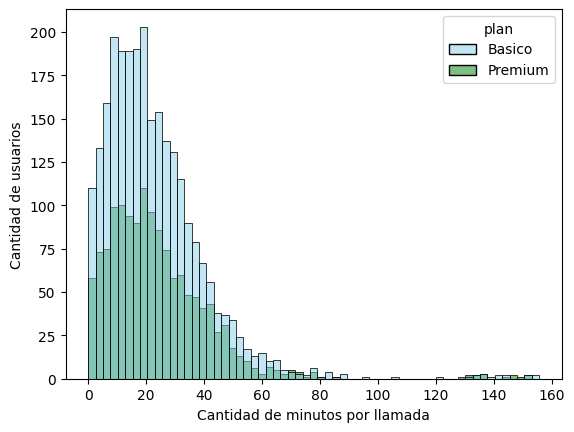

In [49]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data= user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue','green'])
plt.xlabel('Cantidad de minutos por llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights: 
- La duración de las llamadas presenta una distribución asimétrica positiva, donde la mayoría de los usuarios concentra sus llamadas entre 5 y 30 minutos, mientras que un grupo reducido realiza llamadas considerablemente más largas. Ambos planes muestran patrones muy similares, aunque los usuarios del plan Premium parecen tener una mayor proporción de llamadas extensas, alcanzando valores cercanos a 150 minutos por llamada.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

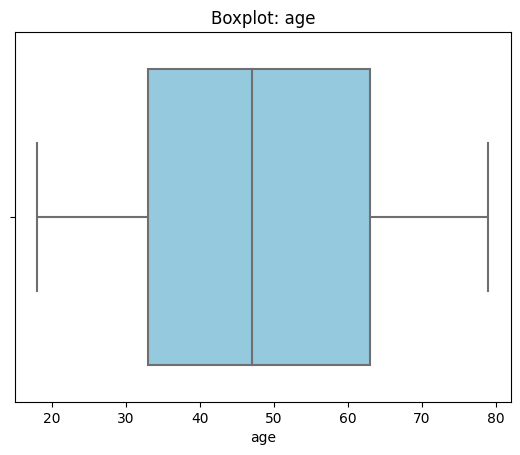

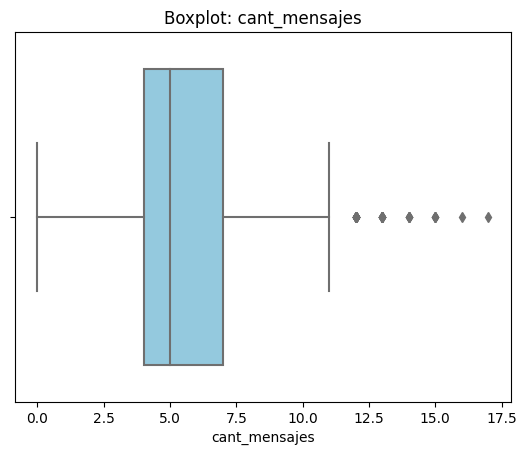

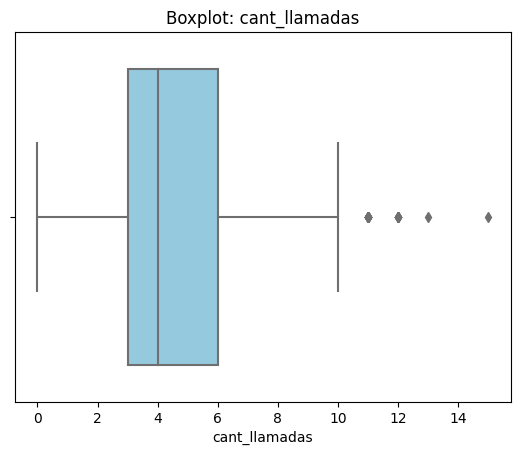

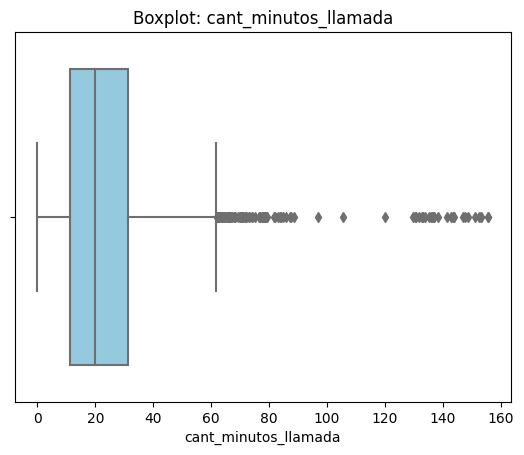

In [50]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.show()

💡Insights: 
- Age: No presenta outliers
- cant_mensajes: Presenta outliers
- cant_llamadas: Presenta outliers
- cant_minutos_llamada: Presenta outliers

In [77]:

# Calcular límites con el método IQR
columnas_limites = [ 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    print(col,'Q1:',Q1)
    Q3 = user_profile[col].quantile(0.75)
    print(col,'Q3:', Q3)
    IQR = Q3 - Q1
    print('IQR: ', IQR)
    limite_inferior = Q1 -1.5 * IQR
    print('Limite inferior:',col,limite_inferior)
    limite_superior= Q3 + 1.5* IQR
    print('Limite superior:',col,limite_superior)

cant_mensajes Q1: 4.0
cant_mensajes Q3: 7.0
IQR:  3.0
Limite inferior: cant_mensajes -0.5
Limite superior: cant_mensajes 11.5
cant_llamadas Q1: 3.0
cant_llamadas Q3: 6.0
IQR:  3.0
Limite inferior: cant_llamadas -1.5
Limite superior: cant_llamadas 10.5
cant_minutos_llamada Q1: 11.12
cant_minutos_llamada Q3: 31.415
IQR:  20.295
Limite inferior: cant_minutos_llamada -19.322500000000005
Limite superior: cant_minutos_llamada 61.8575


In [78]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- Mantener: Ya que representan usuarios con un uso intensivo real y pueden aportar información valiosa sobre segmentos de alto consumo.
- cant_llamadas: mantener o no outliers, porqué?
- Mantener: La mayoría de los usuarios realiza entre 3 y 6 llamadas, pero se observan casos de hasta 15 llamadas. Este valor no es excesivamente distante del resto de la distribución y puede corresponder a patrones reales de uso.
- cant_minutos_llamada: mantener o no outliers, porqué?
- Mantener los outliers si el objetivo es comprender el comportamiento real de los usuarios y evaluar el consumo del servicio. Sin embargo, para modelos estadísticos, conviene analizarlos por separado o complementar el análisis con métricas como la mediana.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [113]:
# Crear columna grupo_uso


def grupo_uso(llamadas,mensajes):

    if llamadas < 5 and mensajes < 5:
       return 'Bajo uso'
    elif llamadas < 10 and mensajes < 10:
        return 'Uso medio'
    else: 
        return 'Alto uso'
user_profile['grupo_uso'] = user_profile.apply(lambda x: grupo_uso(x['cant_llamadas'], x['cant_mensajes']),
    axis=1)


In [114]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,date,grupo_uso
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2024-01-01 00:00:00.000000000,Uso medio
1,10001,5,10,33.18,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2024-01-01 00:06:30.969774244,Alto uso
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2024-01-01 00:13:01.939548488,Uso medio
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2024-01-01 00:19:32.909322733,Alto uso
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2024-01-01 00:26:03.879096977,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [116]:
# Crear columna grupo_edad
def grupo_edad(edad):

    if edad < 30:
       return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else: 
        return 'Adulto Mayor'
user_profile['grupo_edad'] = user_profile.apply(lambda x: grupo_edad(x['age']),
    axis=1)

In [117]:
# verificar cambios
user_profile.head()

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada,first_name,last_name,age,city,reg_date,plan,churn_date,date,grupo_uso,grupo_edad
0,10000,7,3,23.70,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,2024-01-01 00:00:00.000000000,Uso medio,Adulto
1,10001,5,10,33.18,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,2024-01-01 00:06:30.969774244,Alto uso,Adulto
2,10002,5,2,10.74,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,2024-01-01 00:13:01.939548488,Uso medio,Adulto
3,10003,11,3,8.99,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,2024-01-01 00:19:32.909322733,Alto uso,Adulto Mayor
4,10004,4,3,8.01,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,2024-01-01 00:26:03.879096977,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

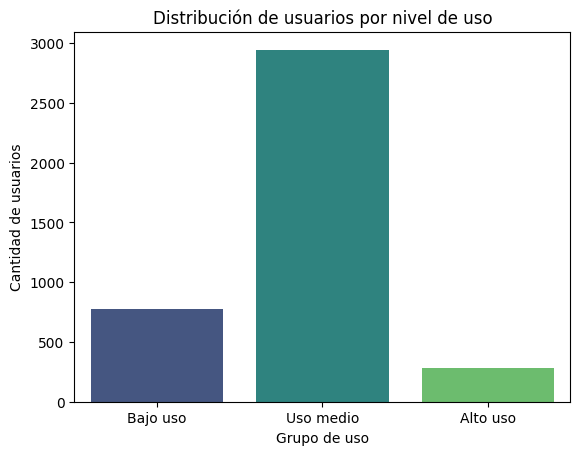

In [118]:
# Visualización de los segmentos por uso
sns.countplot(
    data=user_profile,
    x='grupo_uso',
    order=['Bajo uso', 'Uso medio', 'Alto uso'],
    palette='viridis'
)

plt.title('Distribución de usuarios por nivel de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

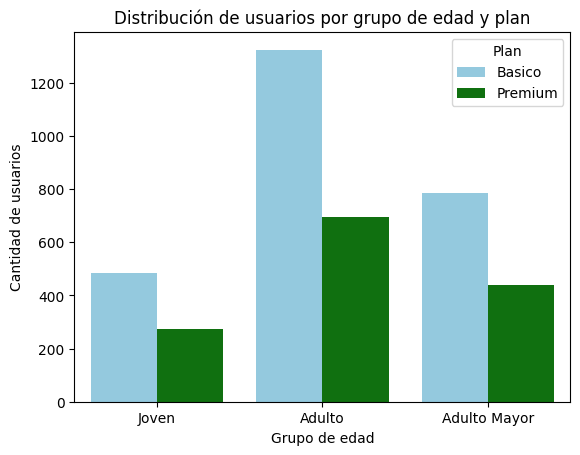

In [119]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    hue='plan',
    order=['Joven', 'Adulto', 'Adulto Mayor'],
    palette=['skyblue', 'green']
)

plt.title('Distribución de usuarios por grupo de edad y plan')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.legend(title='Plan')

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Se identificaron outliers en las variables cantidad de mensajes, cantidad de llamadas y  en minutos por llamada, donde algunas llamadas alcanzaron hasta 155.69 minutos.
No se encontraron evidencias de errores de captura o registros imposibles, por lo que los outliers fueron conservados al representar comportamientos reales de usuarios con consumo intensivo.
La variable minutos por llamada mostró una distribución fuertemente sesgada hacia la derecha, haciendo que el promedio (23.3 minutos) fuera superior a la mediana (19.8 minutos).

🔍 **Segmentos por Edad**
- Se identificaron tres segmentos:

Jóvenes (< 30 años)
Adultos (30-59 años)
Adultos Mayores (≥ 60 años)

La distribución de edades fue relativamente uniforme entre los planes Básico y Premium, sin observarse una concentración marcada de algún grupo de edad en particular en un plan específico.

Los usuarios adultos representan el segmento más amplio de clientes y constituyen la principal base de usuarios de la compañía.


📊 **Segmentos por Nivel de Uso**
-Se clasificó a los usuarios en:
Bajo uso: menos de 5 llamadas y menos de 5 mensajes.
Uso medio: menos de 10 llamadas y menos de 10 mensajes.
Alto uso: 10 o más llamadas o mensajes.

La mayoría de los clientes se concentra en el segmento de uso medio, lo que indica patrones de consumo moderados y estables.

Los usuarios de alto uso representan una proporción menor.

Tanto los planes Básico como Premium presentan patrones de uso similares en llamadas y mensajes, aunque el plan Básico cuenta con una mayor cantidad total de usuarios.


➡️ Esto sugiere que ...
La edad no parece ser un factor determinante en la elección del plan contratado ni en los patrones de consumo observados. En cambio, las diferencias más relevantes se encuentran en la intensidad de uso de los servicios, donde existe un pequeño grupo de usuarios con consumos considerablemente superiores al promedio. Estos usuarios representan una oportunidad para estrategias de monetización y segmentación más específicas.

💡 **Recomendaciones**
- Crear planes orientados a usuarios intensivos, incorporando mayores beneficios en llamadas y servicios complementarios para captar y retener clientes con alto consumo.
- Diseñar ofertas específicas para usuarios de bajo uso, incluyendo planes más económicos y flexibles que reduzcan el riesgo de cancelación.
- Monitorear continuamente los usuarios con consumos extremos, ya que representan oportunidades de ingresos adicionales, pero también pueden generar mayores costos operativos.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---



### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`